# Analyze structured HK diagnostic

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 240)
pd.set_option("display.width", 300)


def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "opinion_dynamics").exists():
            return candidate
    raise RuntimeError("Could not find repository root.")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = REPO_ROOT / "opinion_dynamics" / "experiments" / "results"
RESULTS_DIR = RESULTS_ROOT / "experiment_2026_10_02_structured_hk_diagnostic"
OUT = RESULTS_ROOT / "analysis_2026_10_02_structured_hk_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RESULTS_DIR / "combined_summary.csv")
cov = pd.read_csv(RESULTS_DIR / "coverage_summary.csv")

VARIANT_ORDER = [
    "abundant_random_1k",
    "abundant_random_20k",
    "abundant_trueA_data_1k",
    "abundant_ss_replay_data_1k",
    "ss_exact_offline_1k",
    "ss_exact_offline_20k",
    "single_shot_online",
]

print("Result rows:", len(df))
print("Coverage rows:", len(cov))


C:\Users\Chainsword\AppData\Local\Temp\ipykernel_23616\837968692.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Result rows: 315
Coverage rows: 120


In [2]:

# Main control comparison.
overall = (
    df.groupby("variant", as_index=False)
    .agg(
        n=("mean_end", "size"),
        control=("mean_end", "mean"),
        control_std=("mean_end", "std"),
        rowTV=("row_TV", "mean"),
        edge_AP=("edge_AP", "mean"),
        true_edge_mass=("true_edge_mass", "mean"),
        effective_neighbors=("effective_neighbors", "mean"),
        prediction_ratio=("model_over_identity", "mean"),
    )
)
overall["order"] = overall["variant"].map(
    {v: i for i, v in enumerate(VARIANT_ORDER)}
)
overall = overall.sort_values("order").drop(columns="order")
overall.to_csv(OUT / "overall_variant_comparison.csv", index=False)
display(overall.round(6))


,variant,n,control,control_std,rowTV,edge_AP,true_edge_mass,effective_neighbors,prediction_ratio
0,abundant_random_1k,45,0.622440,0.003421,0.725977,0.535402,0.394784,12.384141,1.081566
1,abundant_random_20k,45,0.895149,0.003847,0.041935,0.996577,0.965967,3.016478,0.138159
3,abundant_trueA_data_1k,45,0.888360,0.004389,0.618309,0.668706,0.489738,10.710608,0.905411
2,abundant_ss_replay_data_1k,45,0.873950,0.025647,0.665917,0.632636,0.448234,11.696719,0.912693
5,ss_exact_offline_1k,45,0.867118,0.027826,0.673666,0.625240,0.439187,11.872572,0.911046
6,ss_exact_offline_20k,45,0.894547,0.004028,0.126038,0.931243,0.934517,2.666581,0.100899
4,single_shot_online,45,0.876433,0.005853,0.125078,0.920326,0.941029,2.547043,0.074967


In [3]:

# The direct diagnostic deltas.
wide = df.pivot_table(
    index=[
        "environment_id",
        "family",
        "environment_seed",
        "learning_seed",
    ],
    columns="variant",
    values="mean_end",
    aggfunc="first",
).reset_index()

delta_specs = {
    "more_optimization_random_20k_minus_1k":
        ("abundant_random_20k", "abundant_random_1k"),
    "trueA_collection_minus_random":
        ("abundant_trueA_data_1k", "abundant_random_1k"),
    "ss_replay_collection_minus_random":
        ("abundant_ss_replay_data_1k", "abundant_random_1k"),
    "exact_ss_data_1k_minus_random":
        ("ss_exact_offline_1k", "abundant_random_1k"),
    "exact_ss_data_20k_minus_1k":
        ("ss_exact_offline_20k", "ss_exact_offline_1k"),
    "online_ss_minus_offline_ss_20k":
        ("single_shot_online", "ss_exact_offline_20k"),
}

for name, (a, b) in delta_specs.items():
    wide[name] = wide[a] - wide[b]

delta_cols = list(delta_specs)
deltas = pd.DataFrame({
    "diagnostic": delta_cols,
    "mean_delta_control": [wide[c].mean() for c in delta_cols],
    "median_delta_control": [wide[c].median() for c in delta_cols],
    "min_delta_control": [wide[c].min() for c in delta_cols],
    "max_delta_control": [wide[c].max() for c in delta_cols],
})
deltas.to_csv(OUT / "diagnostic_control_deltas.csv", index=False)
display(deltas.round(6))


,diagnostic,mean_delta_control,median_delta_control,min_delta_control,max_delta_control
0,more_optimization_random_20k_minus_1k,0.272708,0.273771,0.262603,0.281599
1,trueA_collection_minus_random,0.265920,0.266934,0.254753,0.277366
2,ss_replay_collection_minus_random,0.251510,0.258034,0.173628,0.278859
3,exact_ss_data_1k_minus_random,0.244677,0.251915,0.173604,0.278859
4,exact_ss_data_20k_minus_1k,0.027430,0.021726,-0.005579,0.097800
5,online_ss_minus_offline_ss_20k,-0.018115,-0.017360,-0.029970,-0.002119


In [4]:

# Same control comparison by structured HK family.
family = (
    df.groupby(["family", "variant"], as_index=False)
    .agg(
        control=("mean_end", "mean"),
        rowTV=("row_TV", "mean"),
        edge_AP=("edge_AP", "mean"),
        prediction_ratio=("model_over_identity", "mean"),
    )
)
family["order"] = family["variant"].map(
    {v: i for i, v in enumerate(VARIANT_ORDER)}
)
family = family.sort_values(["family", "order"]).drop(columns="order")
family.to_csv(OUT / "variant_comparison_by_family.csv", index=False)
display(
    family.pivot(
        index="variant",
        columns="family",
        values="control",
    ).reindex(VARIANT_ORDER).round(6)
)


family,dense_weak_bridge,paired_bridge,ring_bridge
variant,,,
abundant_random_1k,0.620320,0.622504,0.624497
abundant_random_20k,0.899051,0.896214,0.890181
abundant_trueA_data_1k,0.892856,0.889212,0.883012
abundant_ss_replay_data_1k,0.883543,0.877833,0.860473
ss_exact_offline_1k,0.878089,0.872010,0.851254
ss_exact_offline_20k,0.898361,0.895402,0.889878
single_shot_online,0.880891,0.877418,0.870989


In [5]:

# Data-distribution / HK-threshold coverage.
coverage = (
    cov.groupby("data_source", as_index=False)
    .agg(
        n=("bridge_active_fraction", "size"),
        bridge_active=("bridge_active_fraction", "mean"),
        bridge_near_eps=("bridge_near_eps_0p025_fraction", "mean"),
        bridge_gap_mean=("bridge_gap_mean", "mean"),
        bridge_gap_q10=("bridge_gap_q10", "mean"),
        bridge_gap_q50=("bridge_gap_q50", "mean"),
        bridge_gap_q90=("bridge_gap_q90", "mean"),
        edge_active=("edge_active_fraction", "mean"),
        edge_near_eps=("edge_near_eps_0p025_fraction", "mean"),
    )
)
coverage.to_csv(OUT / "threshold_coverage_comparison.csv", index=False)
display(coverage.round(6))


,data_source,n,bridge_active,bridge_near_eps,bridge_gap_mean,bridge_gap_q10,bridge_gap_q50,bridge_gap_q90,edge_active,edge_near_eps
0,abundant_random_25x20,15,0.492400,0.033093,0.196951,0.011293,0.237629,0.350712,0.982716,0.001163
1,abundant_single_shot_action_replay_25x20,45,0.851111,0.003316,0.089015,0.015877,0.037322,0.298645,0.994770,0.000120
2,abundant_trueA_control_25x20,15,0.918960,0.029707,0.066877,0.015030,0.030623,0.206481,0.997136,0.001000
3,single_shot_exact,45,0.851111,0.003333,0.089300,0.015970,0.037362,0.296152,0.994770,0.000120


In [6]:

# Decompose effective-matrix error on the exact successful single-shot states.
# Interpretation:
# - trueA_alpha much lower than full -> A_hat is the larger bottleneck.
# - Ahat_true_gate much lower than full -> learned alpha/gating is the larger bottleneck.
model_df = df[df["variant"] != "single_shot_online"].copy()

matrix = (
    model_df.groupby("variant", as_index=False)
    .agg(
        M_full=("M_MAE_all", "mean"),
        M_true_support=("M_MAE_true_support", "mean"),
        M_trueA_alpha=("M_MAE_trueA_alpha", "mean"),
        M_Ahat_true_gate=("M_MAE_Ahat_true_gate", "mean"),
        inactive_leak=("inactive_true_edge_mass_fraction", "mean"),
        nonedge_leak=("spurious_nonedge_mass_fraction", "mean"),
        alpha_gate_AP=("alpha_gate_AP_on_true_edges", "mean"),
        alpha_active=("alpha_active_mean", "mean"),
        alpha_inactive=("alpha_inactive_mean", "mean"),
        alpha_ratio=("alpha_active_over_inactive", "mean"),
    )
)

order = [v for v in VARIANT_ORDER if v != "single_shot_online"]
matrix["order"] = matrix["variant"].map({v: i for i, v in enumerate(order)})
matrix = matrix.sort_values("order").drop(columns="order")
matrix["improvement_if_true_A"] = matrix["M_full"] - matrix["M_trueA_alpha"]
matrix["improvement_if_true_gate"] = matrix["M_full"] - matrix["M_Ahat_true_gate"]
matrix.to_csv(OUT / "effective_matrix_diagnostics.csv", index=False)
display(matrix.round(6))


,variant,M_full,M_true_support,M_trueA_alpha,M_Ahat_true_gate,inactive_leak,nonedge_leak,alpha_gate_AP,alpha_active,alpha_inactive,alpha_ratio,improvement_if_true_A,improvement_if_true_gate
0,abundant_random_1k,0.074698,0.242531,0.056620,0.099154,0.001065,0.593184,0.997898,0.206116,0.176600,1.140538,0.018078,-0.024456
1,abundant_random_20k,0.303608,1.066101,0.304297,0.005750,0.000129,0.031028,1.000000,5.286067,0.406157,13.468877,-0.000689,0.297858
3,abundant_trueA_data_1k,0.146306,0.194569,0.109796,0.084581,0.000198,0.490775,0.999992,2.549928,0.772853,3.292748,0.036510,0.061725
2,abundant_ss_replay_data_1k,0.124693,0.224361,0.063148,0.090974,0.000394,0.531607,1.000000,1.698856,0.542170,2.998435,0.061546,0.033720
4,ss_exact_offline_1k,0.113542,0.214415,0.048853,0.091985,0.000437,0.541324,1.000000,1.437718,0.530966,2.630776,0.064689,0.021557
5,ss_exact_offline_20k,0.303450,1.011605,0.302820,0.017743,0.000290,0.063050,1.000000,5.266857,1.184981,4.633988,0.000630,0.285707


In [7]:

# Compact seed robustness.
seed_table = (
    df.groupby(["learning_seed", "variant"], as_index=False)
    .agg(control=("mean_end", "mean"))
)
display(
    seed_table.pivot(
        index="variant",
        columns="learning_seed",
        values="control",
    ).reindex(VARIANT_ORDER).round(6)
)
seed_table.to_csv(OUT / "control_by_seed.csv", index=False)


learning_seed,0,1,2
variant,,,
abundant_random_1k,0.622412,0.621803,0.623107
abundant_random_20k,0.895149,0.895149,0.895149
abundant_trueA_data_1k,0.886671,0.888639,0.889770
abundant_ss_replay_data_1k,0.862870,0.874572,0.884408
ss_exact_offline_1k,0.855832,0.863363,0.882158
ss_exact_offline_20k,0.894243,0.895165,0.894235
single_shot_online,0.876773,0.876732,0.875793


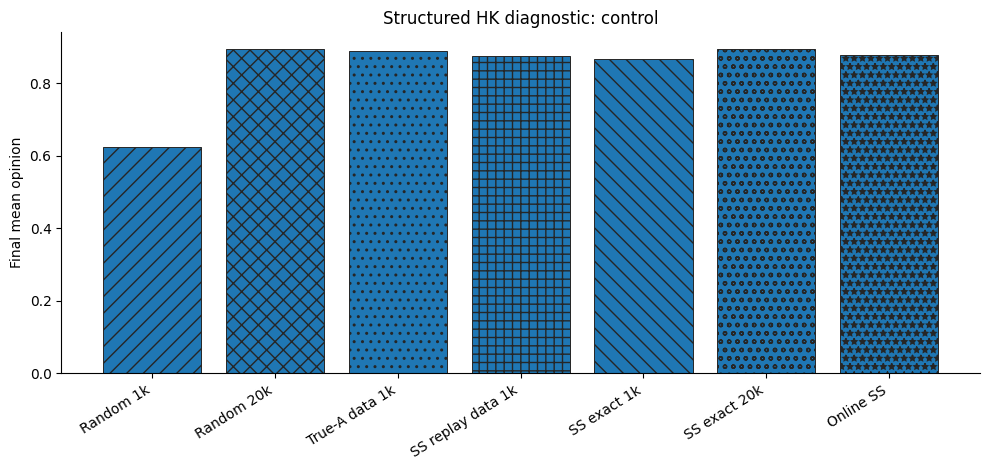

In [8]:

# Grayscale control plot.
plot = overall.set_index("variant").reindex(VARIANT_ORDER).reset_index()
x = np.arange(len(plot))

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(
    x,
    plot["control"],
    edgecolor=".15",
    linewidth=0.7,
)
hatches = ["//", "xx", "..", "++", "\\\\", "oo", "**"]
for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Random 1k",
        "Random 20k",
        "True-A data 1k",
        "SS replay data 1k",
        "SS exact 1k",
        "SS exact 20k",
        "Online SS",
    ],
    rotation=32,
    ha="right",
)
ax.set_ylabel("Final mean opinion")
ax.set_title("Structured HK diagnostic: control")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "hk_diagnostic_control.png", dpi=300, bbox_inches="tight")
plt.show()


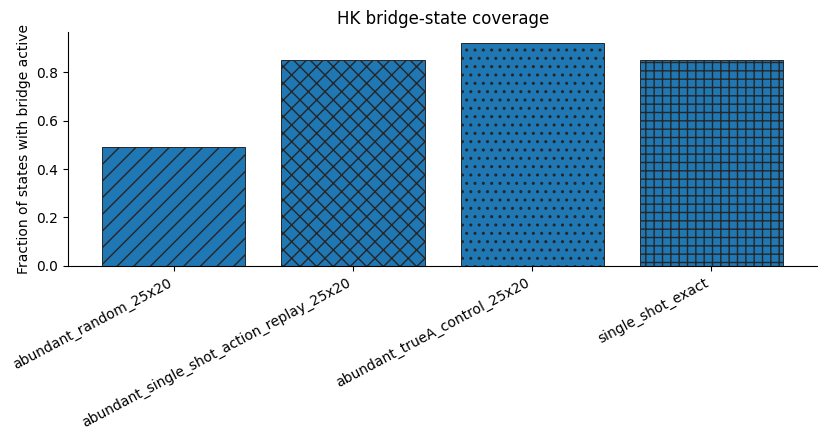

Analysis outputs: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\analysis_2026_10_02_structured_hk_diagnostic


In [9]:

# Coverage plot: the key bridge (hub 0 <-> hub 7).
cov_plot = coverage.sort_values("data_source").reset_index(drop=True)
x = np.arange(len(cov_plot))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(
    x,
    cov_plot["bridge_active"],
    edgecolor=".15",
    linewidth=0.7,
)
for bar, hatch in zip(bars, ["//", "xx", "..", "++"]):
    bar.set_hatch(hatch)

ax.set_xticks(x)
ax.set_xticklabels(
    cov_plot["data_source"],
    rotation=28,
    ha="right",
)
ax.set_ylabel("Fraction of states with bridge active")
ax.set_title("HK bridge-state coverage")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "hk_bridge_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

print("Analysis outputs:", OUT)
